
# Milestone: RFM Scoring & Customer Segmentation


## Objective

Assign RFM scores to customers and develop actionable segments based on purchasing behaviour. Evaluate segment size, revenue contribution, and marketing opportunities.




## Analytical Approach

RFM analysis evaluates customers across three dimensions:

| Dimension | Definition | Scoring Direction |
|---|---|---|
| Recency (R) | Days since the customer's last purchase | Lower recency = Higher score |
| Frequency (F) | Number of completed purchases | Higher frequency = Higher score |
| Monetary (M) | Net spending after successful refunds | Higher monetary = Higher score |




## 1. Setup and Data Loading


In [1]:

# Standard library imports
import sys
from pathlib import Path

# Third-party imports
import pandas as pd
import numpy as np
from sqlalchemy import text
# Add project root to Python's import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))


from src.db import engine, test_connection
test_connection()


('neondb', 'ecom', 'PostgreSQL 18.7 (84da7d8) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit')


## 2. RFM Dataset Validation

### Load RFM Dataset

Recreate the customer-level RFM dataset using a consolidated SQL query.

Use delivered orders for Recency and Frequency, and net spending after successful refunds for Monetary.


In [2]:
# Inspect relevant source table columns
query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ecom'
  AND table_name IN ('orders', 'refunds')
ORDER BY table_name, ordinal_position;
"""
schema_df = pd.read_sql(text(query), engine)
display(schema_df)


,table_name,column_name,data_type
0,orders,order_id,bigint
1,orders,order_number,text
2,orders,created_at,timestamp with time zone
3,orders,customer_id,bigint
4,orders,session_id,uuid
5,orders,cart_id,uuid
6,orders,price_list_id,bigint
7,orders,status,text
8,orders,subtotal,numeric
9,orders,discount,numeric



## Build Customer-Level RFM Dataset

Aggregate delivered orders and successful refunds at the customer level to calculate the RFM features.


In [3]:
# Define the snapshot date
snapshot_date = '2026-06-15'

# Build customer-level RFM features
rfm_query = """
WITH delivered_orders AS (
    SELECT
        order_id,
        customer_id,
        created_at::date AS order_date,
        total
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
),
customer_orders AS (
    SELECT
        customer_id,
        MAX(order_date) AS last_purchase_date,
        COUNT(order_id) AS frequency,
        SUM(total) AS gross_monetary
    FROM delivered_orders
    GROUP BY customer_id
),
customer_refunds AS (
    SELECT
        d.customer_id,
        SUM(r.amount) AS successful_refunds
    FROM delivered_orders d
    JOIN ecom.refunds r
        ON d.order_id = r.order_id
    WHERE LOWER(TRIM(r.status)) = 'succeeded'
    GROUP BY d.customer_id
)
SELECT
    o.customer_id,
    o.last_purchase_date,
    o.frequency,
    o.gross_monetary,
    COALESCE(r.successful_refunds, 0) AS successful_refunds,
    o.gross_monetary - COALESCE(r.successful_refunds, 0)
        AS net_monetary,
    CAST(:snapshot_date AS date) - o.last_purchase_date
        AS recency
FROM customer_orders o
LEFT JOIN customer_refunds r
    ON o.customer_id = r.customer_id
ORDER BY o.customer_id;
"""

# Load the dataset
rfm_df = pd.read_sql(
    text(rfm_query),
    engine,
    params={"snapshot_date": snapshot_date}
)

# Preview
display(rfm_df.head())
print("Dataset shape:", rfm_df.shape)


,customer_id,last_purchase_date,frequency,gross_monetary,successful_refunds,net_monetary,recency
0,1,2026-05-25,4,78694.94,0.0,78694.94,21
1,2,2026-05-07,1,3181.28,0.0,3181.28,39
2,4,2026-05-27,3,26601.92,0.0,26601.92,19
3,7,2026-05-09,1,1010.82,0.0,1010.82,37
4,9,2026-04-26,2,4302.28,0.0,4302.28,50


Dataset shape: (6052, 7)



## Validate RFM Dataset

Check record counts, uniqueness, missing values, and feature distributions before scoring.


In [4]:

# Dataset dimensions
print("Rows and columns:", rfm_df.shape)

# Unique customers
print("Unique customers:", rfm_df['customer_id'].nunique())

# Duplicate customer records
print("Duplicate customers:", rfm_df['customer_id'].duplicated().sum())

# Missing values
display(rfm_df.isnull().sum())

# Feature summary
display(
    rfm_df[
        ['recency', 'frequency', 'gross_monetary',
         'successful_refunds', 'net_monetary']
    ].describe().T
)


Rows and columns: (6052, 7)
Unique customers: 6052
Duplicate customers: 0


customer_id           0
last_purchase_date    0
frequency             0
gross_monetary        0
successful_refunds    0
net_monetary          0
recency               0
dtype: int64

,count,mean,std,min,25%,50%,75%,max
recency,6052.0,41.057336,25.480830,1.00,19.000,39.00,64.000,91.00
frequency,6052.0,3.301223,5.768117,1.00,1.000,1.00,4.000,102.00
gross_monetary,6052.0,24854.302323,47119.332451,175.82,4245.345,11441.87,28363.070,795745.26
successful_refunds,6052.0,174.866461,1231.421287,0.00,0.000,0.00,0.000,24851.78
net_monetary,6052.0,24679.435863,46884.823779,0.00,4184.280,11326.82,28085.885,787135.98



## 3. RFM Scoring

### Feature Distribution Checks

Examine repeated values, zero monetary balances, and quantile boundaries to determine suitable scoring bins.


In [5]:

# Frequency distribution
display(
    rfm_df['frequency']
    .value_counts()
    .sort_index()
    .rename_axis('frequency')
    .to_frame('customer_count')
)

# Monetary edge cases
print("Zero net monetary:", (rfm_df['net_monetary'] == 0).sum())
print("Negative net monetary:", (rfm_df['net_monetary'] < 0).sum())

# Quantile boundaries
quantiles = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

for feature in ['recency', 'frequency', 'net_monetary']:
    print(f"\n{feature.upper()} quantile boundaries:")
    print(rfm_df[feature].quantile(quantiles))
    print("Unique boundaries:",rfm_df[feature].quantile(quantiles).nunique())


,customer_count
frequency,
1,3034
2,717
3,662
4,514
5,338
...,...
80,1
90,1
91,1


Zero net monetary: 17
Negative net monetary: 0

RECENCY quantile boundaries:
0.0     1.0
0.2    15.0
0.4    29.0
0.6    49.0
0.8    68.0
1.0    91.0
Name: recency, dtype: float64
Unique boundaries: 6

FREQUENCY quantile boundaries:
0.0      1.0
0.2      1.0
0.4      1.0
0.6      2.0
0.8      4.0
1.0    102.0
Name: frequency, dtype: float64
Unique boundaries: 4

NET_MONETARY quantile boundaries:
0.0         0.000
0.2      3183.876
0.4      7840.392
0.6     16515.752
0.8     33778.004
1.0    787135.980
Name: net_monetary, dtype: float64
Unique boundaries: 6



### Frequency Distribution

Inspect purchase frequency to determine an appropriate scoring strategy for one-time and repeat customers.


In [6]:

# Frequency distribution
frequency_dist = (
    rfm_df['frequency']
    .value_counts()
    .sort_index()
    .rename_axis('frequency')
    .reset_index(name='customer_count')
)

frequency_dist['customer_pct'] = (
    frequency_dist['customer_count'] / len(rfm_df) * 100
)

display(frequency_dist)

# Separate one-time and repeat customers
print("One-time buyers:",
      (rfm_df['frequency'] == 1).sum())

print("Repeat buyers:",
      (rfm_df['frequency'] > 1).sum())


,frequency,customer_count,customer_pct
0,1,3034,50.132188
1,2,717,11.847323
2,3,662,10.938533
3,4,514,8.493060
4,5,338,5.584931
...,...,...,...
59,80,1,0.016523
60,90,1,0.016523
61,91,1,0.016523
62,95,1,0.016523


One-time buyers: 3034
Repeat buyers: 3018




### Frequency Scoring Strategy

Assign F1 to one-time buyers and divide repeat buyers into four quantile-based groups.


In [7]:

# Isolate repeat buyers
repeat_buyers = rfm_df.loc[
    rfm_df['frequency'] > 1, 'frequency'
]
# Calculate four quantile boundaries
frequency_quantiles = repeat_buyers.quantile(
    [0, 0.25, 0.50, 0.75, 1.0]
)

display(frequency_quantiles)

print(
    "Unique boundaries:",
    frequency_quantiles.nunique()
)

# Test four quantile bins
repeat_frequency_bins = pd.qcut(
    repeat_buyers,
    q=4,
    labels=[2, 3, 4, 5]
)

# Inspect resulting score distribution
display(
    repeat_frequency_bins
    .value_counts()
    .sort_index()
    .rename_axis('frequency_score')
    .to_frame('customer_count')
)


0.00      2.0
0.25      3.0
0.50      4.0
0.75      6.0
1.00    102.0
Name: frequency, dtype: float64

Unique boundaries: 5


,customer_count
frequency_score,
2,1379
3,514
4,539
5,586



### Recency and Monetary Scoring

Evaluate five-bin quantile distributions for Recency and Monetary.


In [8]:

# Recency scoring: invert the direction
rfm_df['R_score'] = pd.qcut(
    rfm_df['recency'],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Monetary scoring: natural direction
rfm_df['M_score'] = pd.qcut(
    rfm_df['net_monetary'],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)  

# Inspect score distributions
print("Recency score distribution:")
display(rfm_df['R_score'].value_counts().sort_index())

print("Monetary score distribution:")
display(rfm_df['M_score'].value_counts().sort_index())


Recency score distribution:


R_score
1    1132
2    1232
3    1221
4    1250
5    1217
Name: count, dtype: int64

Monetary score distribution:


M_score
1    1211
2    1210
3    1210
4    1210
5    1211
Name: count, dtype: int64


### Recency and Monetary Scoring Rationale

Both features were divided into five quantile-based groups using `pd.qcut()`.

- **Recency:** Scores were assigned in reverse order because fewer days since the last purchase indicates more recent activity.
- **Monetary:** Scores were assigned in ascending order because higher net spending indicates greater customer value.

Both features produced five distinct bins with approximately equal customer counts.



### Assign Frequency Scores

Assign F1 to one-time buyers and F2–F5 to repeat buyers using four quantile bins.


In [9]:
# Initialize frequency scores
rfm_df['F_score'] = np.nan

# One-time buyers
rfm_df.loc[rfm_df['frequency'] == 1, 'F_score'] = 1

# Repeat buyers: four quantile groups
repeat_mask = rfm_df['frequency'] > 1

rfm_df.loc[repeat_mask, 'F_score'] = pd.qcut(
    rfm_df.loc[repeat_mask, 'frequency'],
    q=4,
    labels=[2, 3, 4, 5]
).astype(int)

# Convert scores to integers
rfm_df['F_score'] = rfm_df['F_score'].astype(int)

# Validate frequency scores
display(rfm_df['F_score'].value_counts().sort_index())


F_score
1    3034
2    1379
3     514
4     539
5     586
Name: count, dtype: int64


### Frequency Scoring Rationale

One-time buyers were assigned F1 separately because 50.13% of customers had purchased only once.

The remaining repeat buyers were divided into four quantile-based groups using `pd.qcut()`.


| F-score | Frequency range |
|---|---|
| F1 | 1 order |
| F2 | 2–3 orders |
| F3 | 4 orders |
| F4 | 5–6 orders |
| F5 | 7+ orders |

Higher frequency scores indicate more repeat purchases.



## 4. Combined RFM Profiles

Combine individual scores into an RFM string and composite score for customer profiling.


In [10]:

# Combined RFM string
rfm_df['RFM_string'] = (
    rfm_df['R_score'].astype(str)
    + rfm_df['F_score'].astype(str)
    + rfm_df['M_score'].astype(str)
)

# Composite RFM score
rfm_df['RFM_score'] = (
    rfm_df['R_score'].astype(int)
    + rfm_df['F_score']
    + rfm_df['M_score'].astype(int)
)

# Preview
display(
    rfm_df[
        ['customer_id', 'recency', 'frequency',
         'net_monetary', 'R_score', 'F_score',
         'M_score', 'RFM_string', 'RFM_score']
    ].head(10)
)


,customer_id,recency,frequency,net_monetary,R_score,F_score,M_score,RFM_string,RFM_score
0,1,21,4,78694.94,4,3,5,435,12
1,2,39,1,3181.28,3,1,1,311,5
2,4,19,3,26601.92,4,2,4,424,10
3,7,37,1,1010.82,3,1,1,311,5
4,9,50,2,4302.28,2,2,2,222,6
5,10,49,4,30018.02,3,3,4,334,10
6,13,48,2,32391.74,3,2,4,324,9
7,14,26,1,6958.46,4,1,2,412,7
8,16,31,13,70121.50,3,5,5,355,13
9,18,39,1,11324.46,3,1,3,313,7



### RFM Profile Interpretation

The three individual scores are combined into:

- **RFM String:** A three-digit representation of Recency, Frequency and Monetary scores (e.g., 555).
- **Composite Score:** The sum of the three scores, ranging from 3 to 15.

The RFM string preserves individual customer behaviour, while the composite score provides an overall summary.



### RFM Scoring Validation

Verify score completeness, valid score ranges, and the distribution of combined RFM scores.


In [11]:

# Check missing scores
print("Missing RFM scores:")
display(rfm_df[['R_score', 'F_score', 'M_score']].isnull().sum())

# Check individual score ranges
print("Score ranges:")
display(rfm_df[['R_score', 'F_score', 'M_score']].agg(['min', 'max']))

# Check composite score range
print("Composite score range:")
print(rfm_df['RFM_score'].min(), "to", rfm_df['RFM_score'].max())

# Check customer uniqueness
print("Customer records:", len(rfm_df))
print("Unique customers:", rfm_df['customer_id'].nunique())

# Composite score distribution
display(
    rfm_df['RFM_score']
    .value_counts()
    .sort_index()
    .rename_axis('RFM_score')
    .to_frame('customer_count')
)


Missing RFM scores:


R_score    0
F_score    0
M_score    0
dtype: int64

Score ranges:


,R_score,F_score,M_score
min,1,1,1
max,5,5,5


Composite score range:
3 to 15
Customer records: 6052
Unique customers: 6052


,customer_count
RFM_score,
3,330
4,538
5,680
6,734
7,748
8,601
9,492
10,454
11,380


## 5. RFM Combination Analysis
Examine the distribution and revenue contribution of individual RFM profiles to identify meaningful customer groups.


In [12]:
# Count customers by RFM combination
rfm_combinations = (
    rfm_df.groupby('RFM_string')
    .agg(
        customer_count=('customer_id', 'nunique'),
        net_revenue=('net_monetary', 'sum'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('net_monetary', 'mean')
    )
    .reset_index()
    .sort_values('customer_count', ascending=False)
)

# Customer and revenue contribution percentages
rfm_combinations['customer_pct'] = (
    rfm_combinations['customer_count']
    / rfm_df['customer_id'].nunique() * 100
)

rfm_combinations['revenue_pct'] = (
    rfm_combinations['net_revenue']
    / rfm_df['net_monetary'].sum() * 100
)

display(rfm_combinations.head(20))
print("Total distinct RFM combinations:", len(rfm_combinations))


,RFM_string,customer_count,net_revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
0,111,330,525178.88,78.681818,1.000000,1591.451152,5.452743,0.351620
96,555,298,42588291.62,7.691275,18.805369,142913.730268,4.923992,28.513864
18,211,277,429229.81,60.433213,1.000000,1549.566101,4.576999,0.287379
1,112,250,1339510.02,79.220000,1.000000,5358.040080,4.130866,0.896833
38,311,232,356618.82,39.698276,1.000000,1537.150086,3.833443,0.238765
19,212,232,1212097.25,60.564655,1.000000,5224.557112,3.833443,0.811528
39,312,179,947628.55,39.122905,1.000000,5294.014246,2.957700,0.634460
57,411,178,284906.43,22.185393,1.000000,1600.597921,2.941176,0.190752
58,412,156,821127.98,22.108974,1.000000,5263.640897,2.577660,0.549765
2,113,154,1691562.18,78.350649,1.000000,10984.170000,2.544613,1.132541


Total distinct RFM combinations: 97



### Revenue Contribution by RFM Profile

Identify the RFM combinations contributing the most net revenue and compare their customer behaviour.


In [13]:

# Top 20 RFM combinations by net revenue
top_revenue_combinations = (
    rfm_combinations
    .sort_values('net_revenue', ascending=False)
    .head(20)
)

display(
    top_revenue_combinations[
        ['RFM_string', 'customer_count', 'customer_pct',
         'net_revenue', 'revenue_pct',
         'avg_recency', 'avg_frequency', 'avg_monetary']
    ]
)

# Compare selected RFM profiles
display(
    rfm_combinations[
        rfm_combinations['RFM_string'].isin(
            ['555', '545', '455', '445', '355']
        )
    ].sort_values('RFM_string')
)


,RFM_string,customer_count,customer_pct,net_revenue,revenue_pct,avg_recency,avg_frequency,avg_monetary
96,555,298,4.923992,42588291.62,28.513864,7.691275,18.805369,142913.730268
76,455,146,2.412426,13694087.86,9.168514,21.561644,11.890411,93795.122329
56,355,67,1.107072,5077781.81,3.399694,38.313433,9.686567,75787.788209
74,445,82,1.354924,4444690.85,2.975825,21.792683,5.439024,54203.546951
94,545,80,1.321877,4171199.64,2.792716,8.575000,5.487500,52139.995500
54,345,60,0.991408,3064576.61,2.051806,40.066667,5.416667,51076.276833
46,324,102,1.685393,2413445.48,1.615859,39.627451,2.588235,23661.230196
34,245,46,0.760079,2377563.76,1.591835,57.326087,5.434783,51686.168696
47,325,46,0.760079,2320163.96,1.553404,41.173913,2.521739,50438.346957
65,424,93,1.536682,2215446.17,1.483293,22.064516,2.655914,23822.001828


,RFM_string,customer_count,net_revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
56,355,67,5077781.81,38.313433,9.686567,75787.788209,1.107072,3.399694
74,445,82,4444690.85,21.792683,5.439024,54203.546951,1.354924,2.975825
76,455,146,13694087.86,21.561644,11.890411,93795.122329,2.412426,9.168514
94,545,80,4171199.64,8.575000,5.487500,52139.995500,1.321877,2.792716
96,555,298,42588291.62,7.691275,18.805369,142913.730268,4.923992,28.513864



### Key Findings

- **RFM 555:** 4.92% of customers contribute 28.51% of net revenue.
- **RFM 455:** 2.41% of customers contribute 9.17% of net revenue.
- **RFM 545:** Despite similar recency to 555, its average frequency and monetary value are substantially lower.

These differences demonstrate why individual RFM dimensions are more informative for segmentation than the composite score alone.



## 6. Customer Segmentation

### Initial Customer Segmentation

Apply five mutually exclusive, behaviour-based rules to group customers into actionable marketing segments.



### Segmentation Strategy

A rule-based approach was selected to consolidate 125 possible RFM combinations into five actionable marketing segments.

- **Champions:** High scores across all three dimensions.
- **Loyal Customers:** Recent and frequent buyers who do not qualify as Champions.
- **At Risk:** Inactive customers with relatively strong historical frequency or spending.
- **Lost:** Inactive customers with low frequency and monetary value.
- **Emerging Customers:** Remaining customers with opportunities for repeat purchases and growth.

Rules are applied in priority order to ensure mutually exclusive segment assignments.


In [14]:
# Define mutually exclusive segment conditions (imp)
champions = (
    (rfm_df['R_score'] >= 4) &
    (rfm_df['F_score'] >= 4) &
    (rfm_df['M_score'] >= 4)
)
loyal = (
    (rfm_df['R_score'] >= 3) &
    (rfm_df['F_score'] >= 4) &
    ~champions
)
at_risk = (
    (rfm_df['R_score'] <= 2) &
    (
        (rfm_df['F_score'] >= 3) |
        (rfm_df['M_score'] >= 3)
    )
)
lost = (
    (rfm_df['R_score'] <= 2) &
    (rfm_df['F_score'] <= 2) &
    (rfm_df['M_score'] <= 2)
)
conditions = [champions, loyal, at_risk, lost]
labels = [
    'Champions',
    'Loyal Customers',
    'At Risk',
    'Lost'
]
rfm_df['segment'] = np.select(
    conditions,
    labels,
    default='Emerging Customers'
)
# Verify segment assignment
display(rfm_df['segment'].value_counts())


segment
Emerging Customers    2696
Lost                  1223
At Risk               1141
Champions              773
Loyal Customers        219
Name: count, dtype: int64


## 7. Segment Performance Analysis


Measure customer distribution, net revenue contribution, and average RFM characteristics for each segment.


In [15]:
# Aggregate segment-level metrics
segment_summary = (
    rfm_df.groupby('segment')
    .agg(
        customer_count=('customer_id', 'nunique'),
        net_revenue=('net_monetary', 'sum'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('net_monetary', 'mean'),
        avg_R_score=('R_score', 'mean'),
        avg_F_score=('F_score', 'mean'),
        avg_M_score=('M_score', 'mean')
    )
    .reset_index()
)
# Calculate customer and revenue contribution
segment_summary['customer_pct'] = (
    segment_summary['customer_count']
    / rfm_df['customer_id'].nunique() * 100
)
segment_summary['revenue_pct'] = (
    segment_summary['net_revenue']
    / rfm_df['net_monetary'].sum() * 100
)
# Sort by revenue contribution
segment_summary = segment_summary.sort_values(
    'net_revenue',
    ascending=False
)
display(segment_summary.round(2))


,segment,customer_count,net_revenue,avg_recency,avg_frequency,avg_monetary,avg_R_score,avg_F_score,avg_M_score,customer_pct,revenue_pct
1,Champions,773,69286251.42,13.67,11.90,89632.93,4.60,4.62,4.78,12.77,46.39
2,Emerging Customers,2696,38815617.27,25.02,1.91,14397.48,3.90,1.60,2.75,44.55,25.99
0,At Risk,1141,26917975.83,67.28,2.43,23591.57,1.57,1.95,3.74,18.85,18.02
4,Loyal Customers,219,10164192.92,36.61,6.78,46411.84,3.15,4.37,4.43,3.62,6.81
3,Lost,1223,4175908.40,70.06,1.13,3414.48,1.47,1.11,1.49,20.21,2.80



### Key Findings

- **Champions:** Contribute 46.39% of net revenue from 12.77% of customers, making them the primary retention priority.
- **Emerging Customers:** Represent the largest segment (44.55%), offering the biggest opportunity to develop repeat purchasing.
- **At Risk:** Contribute 18.02% of revenue despite declining recent activity, making them candidates for targeted win-back campaigns.
- **Lost:** Account for 20.21% of customers but only 2.80% of revenue, suggesting limited potential for expensive reactivation.

Champions and Emerging Customers together contribute 72.38% of net revenue.


### Customer Distribution vs Revenue Contribution

Compare each segment's share of customers with its share of total net revenue.

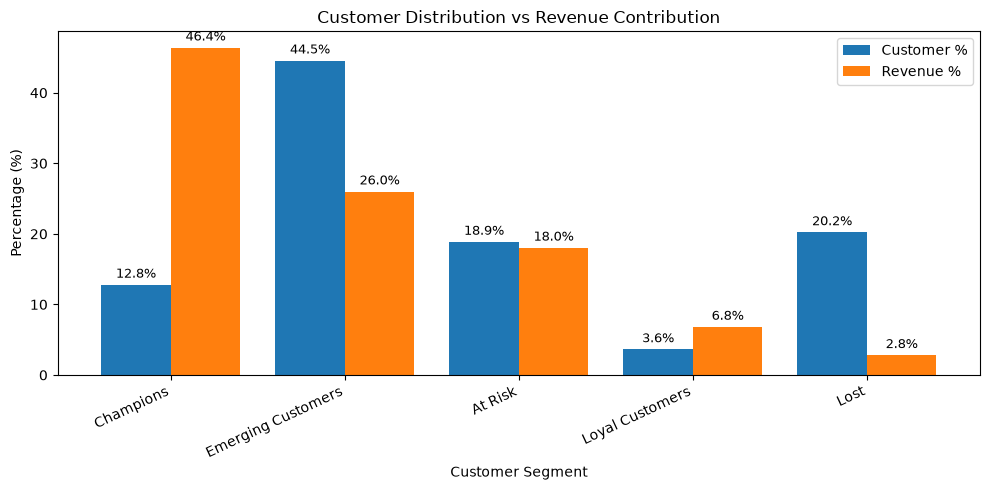

In [28]:
import matplotlib.pyplot as plt

plot_data = segment_summary.set_index('segment')[
    ['customer_pct', 'revenue_pct']
]

ax = plot_data.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.8
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=9
    )

plt.title('Customer Distribution vs Revenue Contribution')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=25, ha='right')
plt.legend(['Customer %', 'Revenue %'])
plt.tight_layout()
plt.show()

### Average Monetary Value by Customer Segment

Compare the average net monetary value of customers across segments.

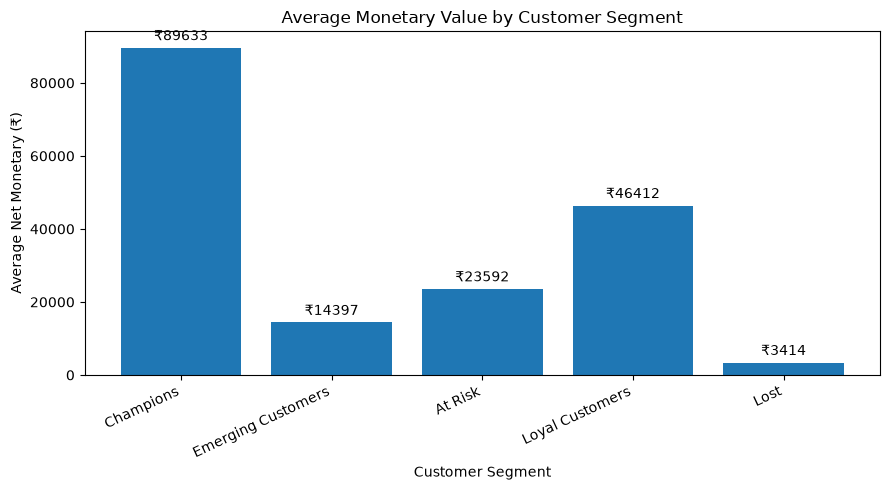

In [29]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    segment_summary['segment'],
    segment_summary['avg_monetary']
)

plt.bar_label(
    bars,
    fmt='₹%.0f',
    padding=3
)

plt.title('Average Monetary Value by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Net Monetary (₹)')
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

## 8. Emerging Customer Behaviour

Examine the most common RFM combinations within Emerging Customers to identify opportunities for repeat purchasing and customer development.


In [30]:

emerging_profiles = (
    rfm_df[rfm_df['segment'] == 'Emerging Customers']
    .groupby('RFM_string')
    .agg(
        customer_count=('customer_id', 'nunique'),
        net_revenue=('net_monetary', 'sum'),
        avg_frequency=('frequency', 'mean'),
        avg_recency=('recency', 'mean'),
        avg_monetary=('net_monetary', 'mean')
    )
    .reset_index()
    .sort_values('customer_count', ascending=False)
)

emerging_profiles['customer_pct'] = (
    emerging_profiles['customer_count']
    / (rfm_df['segment'] == 'Emerging Customers').sum()
    * 100
)

display(emerging_profiles.head(15).round(2))

,RFM_string,customer_count,net_revenue,avg_frequency,avg_recency,avg_monetary,customer_pct
0,311,232,356618.82,1.00,39.70,1537.15,8.61
1,312,179,947628.55,1.00,39.12,5294.01,6.64
14,411,178,284906.43,1.00,22.19,1600.60,6.60
15,412,156,821127.98,1.00,22.11,5263.64,5.79
28,511,136,210860.86,1.00,8.29,1550.45,5.04
29,512,133,667229.28,1.00,8.24,5016.76,4.93
2,313,130,1453600.59,1.00,40.47,11181.54,4.82
16,413,107,1173872.08,1.00,22.31,10970.77,3.97
21,423,105,1241842.98,2.50,21.52,11827.08,3.89
8,324,102,2413445.48,2.59,39.63,23661.23,3.78


### One-time vs Repeat Buyer Analysis

Compare one-time and repeat buyers to identify differences in purchase frequency and revenue contribution.

In [31]:
# Isolate Emerging Customers (imp)
emerging_df = rfm_df[
    rfm_df['segment'] == 'Emerging Customers'
].copy()

# Classify purchase behaviour
emerging_df['purchase_type'] = np.where(
    emerging_df['frequency'] == 1,
    'One-time Buyers',
    'Repeat Buyers'
)

# Compare the two groups
emerging_summary = (
    emerging_df.groupby('purchase_type')
    .agg(
        customer_count=('customer_id', 'nunique'),
        net_revenue=('net_monetary', 'sum'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('net_monetary', 'mean')
    )
    .reset_index()
)

emerging_summary['customer_pct'] = (
    emerging_summary['customer_count']
    / len(emerging_df) * 100
)

emerging_summary['revenue_pct'] = (
    emerging_summary['net_revenue']
    / emerging_df['net_monetary'].sum() * 100
)

display(emerging_summary.round(2))


,purchase_type,customer_count,net_revenue,avg_recency,avg_frequency,avg_monetary,customer_pct,revenue_pct
0,One-time Buyers,1459,10880292.38,25.73,1.00,7457.36,54.12,28.03
1,Repeat Buyers,1237,27935324.89,24.18,2.98,22583.12,45.88,71.97



### Key Findings

One-time Buyers: Represent 54.12% of Emerging Customers but contribute only 28.03% of segment revenue.
Repeat Buyers: Represent 45.88% of Emerging Customers but contribute 71.97% of segment revenue.
Customer Value: Repeat buyers average 2.98 purchases and ₹22,583.12 in net monetary value, compared with ₹7,457.36 for one-time buyers.

**Marketing implication:** Encourage second purchases among one-time buyers and strengthen repeat purchasing through personalized offers and loyalty incentives.



### 9. Final Segment Validation

Verify segment coverage, customer counts, revenue reconciliation, and RFM score consistency.


In [32]:

# Verify segment conditions are mutually exclusive
condition_matrix = pd.DataFrame({
    'Champions': champions,
    'Loyal Customers': loyal,
    'At Risk': at_risk,
    'Lost': lost
})
print("Customers matching multiple rules:",
      (condition_matrix.sum(axis=1) > 1).sum())

# Segment coverage
print("\nTotal customers:", len(rfm_df))
print("Unique customers:", rfm_df['customer_id'].nunique())
print("Assigned customers:", rfm_df['segment'].notna().sum())

# Revenue reconciliation
print("\nTotal net monetary:", rfm_df['net_monetary'].sum())
print("Segment revenue total:", round(segment_summary['net_revenue'].sum(), 2))

# Percentage reconciliation
print("\nCustomer percentage total:",
      segment_summary['customer_pct'].sum())

print("Revenue percentage total:",
      segment_summary['revenue_pct'].sum())

# RFM score validation
print("\nMissing RFM scores:")
display(rfm_df[['R_score', 'F_score', 'M_score']].isna().sum())

print("Composite score range:",
      rfm_df['RFM_score'].min(),
      "to",
      rfm_df['RFM_score'].max())


Customers matching multiple rules: 0

Total customers: 6052
Unique customers: 6052
Assigned customers: 6052

Total net monetary: 149359945.84
Segment revenue total: 149359945.84

Customer percentage total: 100.0
Revenue percentage total: 100.0

Missing RFM scores:


R_score    0
F_score    0
M_score    0
dtype: int64

Composite score range: 3 to 15


## Conclusion

Successfully scored and segmented 6,052 customers into five mutually exclusive behavioural segments. All customers were assigned, RFM scores were complete, and segment-level revenue reconciled with total net monetary value.

The resulting segments provide a foundation for targeted customer retention, re-engagement, and repeat-purchase strategies.